<a href="https://colab.research.google.com/github/taehi5/Esaa_YB/blob/13%EC%A3%BC%EC%B0%A8-%EA%B3%BC%EC%A0%9C/ESAA_YB_Week13_02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

`파이썬 머신러닝 완벽가이드 ch7. 1~4 pg. 431~463`

# 군집화

## K-평균 알고리즘
- 군집화에서 가장 일반적으로 사용되는 알고리즘
- K-Means: 군집 중심점을 선택해 해당 중심에 가장 가까운 포인트들을 선택하는 군집화 기법
   - centroid 가 선택된 포인트의 평균 지점으로 이동
   ➡ 이동된 중심점에서 다시 가까운 포인트 선택
   ➡ 다시 중심점을 평균 지점으로 이동하는 프로세스
   ❗해당 프로세스 반복
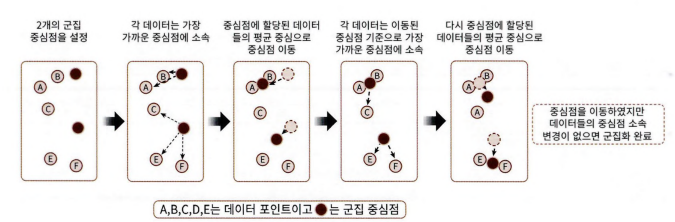

**장점**
- 쉽고 간결

**단점**
- 속성이 많으면 정확도 감소
- 반복이 많으면 시간 증가
- 군집 선택 가이드가 어려움

**사이킷런 KMeans 클래스 소개**
중요 파라미터
- `n_cluster`: 군집화할 개수
- `init`: 초기에 군집 중심점의 좌표 설정 방식
- `max_iter`: 최대 반복 횟수

`fit`이나 `fit_predict`으로 수행하면 됨


In [ ]:
# class sklearn.cluster.KMeans(n_clusters=8, init='k-means++', n_init=10, max_iter=300, tol=0.0001,precompute_distances = 'auto', random_state=None, copy_x=True, n_jobs=1, algorithm='auto')

**K-평균을 이용한 붓꽃 데이터 세트 군집화**


In [ ]:
from sklearn.preprocessing import scale
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
%matplotlib inline

iris = load_iris()
# 더 편리한 데이터 핸들링을 위해 DataFrame으로 변환
irisDF = pd.DataFrame(data=iris.data, columns=['sepal_length', 'sepal_width', 'petal_length',
                                              'petal_width'])
irisDF.head(3)

,sepal_length,sepal_width,petal_length,petal_width
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2


In [ ]:
kmeans = KMeans(n_clusters=3, init='k-means++', max_iter=300, random_state=0)
kmeans.fit(irisDF)

KMeans(n_clusters=3, random_state=0)

In [ ]:
print(kmeans.labels_)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 2 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 2 2 2 0 2 2 2 2
 2 2 0 0 2 2 2 2 0 2 0 2 0 2 2 0 0 2 2 2 2 2 0 2 2 2 2 0 2 2 2 0 2 2 2 0 2
 2 0]


In [ ]:
irisDF['target'] = iris.target
irisDF['cluster']=kmeans.labels_
iris_result = irisDF.groupby(['target','cluster'])['sepal_length'].count()
print(iris_result)

target  cluster
0       1          50
1       0          47
        2           3
2       0          14
        2          36
Name: sepal_length, dtype: int64


In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
pca_transformed = pca.fit_transform(iris.data)

irisDF['pca_x'] = pca_transformed[:, 0]
irisDF['pca_y'] = pca_transformed[:, 1]
irisDF.head(3)

,sepal_length,sepal_width,petal_length,petal_width,target,cluster,pca_x,pca_y
0,5.1,3.5,1.4,0.2,0,1,-2.684126,0.319397
1,4.9,3.0,1.4,0.2,0,1,-2.714142,-0.177001
2,4.7,3.2,1.3,0.2,0,1,-2.888991,-0.144949


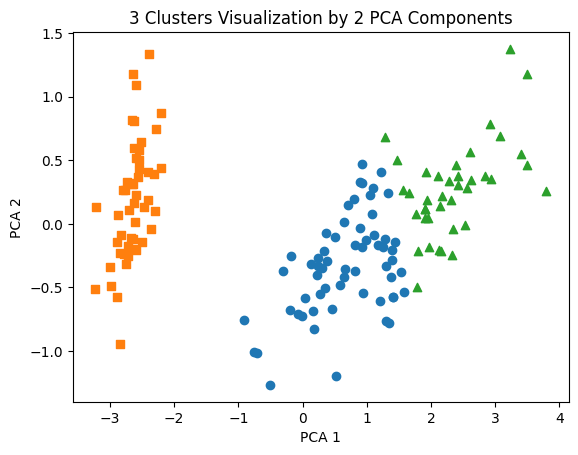

In [ ]:
# 군집 값이 0, 1, 2인 경우마다 별도의 인덱스로 추출
marker0_ind = irisDF[irisDF['cluster']==0].index
marker1_ind = irisDF[irisDF['cluster']==1].index
marker2_ind = irisDF[irisDF['cluster']==2].index

# 군집 값 0, 1, 2에 해당하는 인덱스로 각 군집 레벨의 pca_x, pca_y 값 추출. o, s, ^ 로 마커 표시
plt.scatter(x=irisDF.loc[marker0_ind, 'pca_x'], y=irisDF.loc[marker0_ind, 'pca_y'], marker='o')
plt.scatter(x=irisDF.loc[marker1_ind, 'pca_x'], y=irisDF.loc[marker1_ind, 'pca_y'], marker='s')
plt.scatter(x=irisDF.loc[marker2_ind, 'pca_x'], y=irisDF.loc[marker2_ind, 'pca_y'], marker='^')

plt.xlabel('PCA 1')
plt.ylabel('PCA 2')
plt.title('3 Clusters Visualization by 2 PCA Components')
plt.show()

**군집화 알고리즘 테스트를 위한 데이터 생성**
사이킷런은 군집화 알고리즘을 테스트할 수 있는 가상 데이터 생성 함수를 제공한다.

- `make_blobs()`는 군집별 중심점과 표준편차를 지정할 수 있어 군집의 위치와 퍼짐을 조절하기 쉽다.
- `make_classification()`은 클래스마다 여러 군집을 만들거나 노이즈를 포함한 데이터를 생성하는 데 유용하다.
- `make_circles()`와 `make_moons()`는 원형과 반달 모양 데이터를 생성한다. K-Means처럼 중심점을 기준으로 군집을 나누는 알고리즘을 테스트할 때 사용할 수 있다.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import make_blobs
%matplotlib inline

X, y = make_blobs(n_samples=200, n_features=2, centers=3, cluster_std=0.8, random_state=0)
print(X.shape, y.shape)

# y target 값의 분포를 확인
unique, counts = np.unique(y, return_counts=True)
print(unique, counts)

(200, 2) (200,)
[0 1 2] [67 67 66]


In [ ]:
import pandas as pd

clusterDF = pd.DataFrame(data=X, columns=['ftr1', 'ftr2'])
clusterDF['target'] = y
clusterDF.head(3)

,ftr1,ftr2,target
0,-1.692427,3.622025,2
1,0.697940,4.428867,0
2,1.100228,4.606317,0


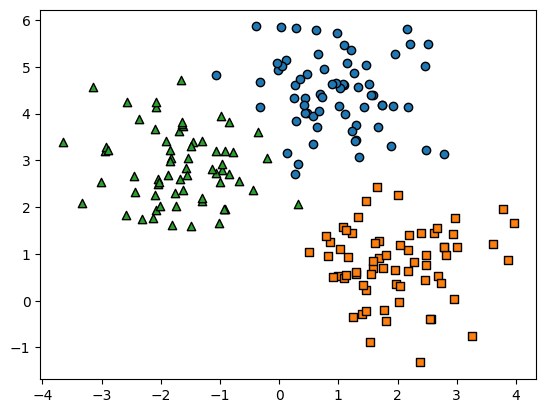

In [ ]:
target_list = np.unique(y)
# 각 타깃별 산점도의 마커 값.
markers=['o', 's', '^', 'P', 'D', 'H', 'x']
# 3개의 군집 영역으로 구분한 데이터 세트를 생성했으므로 target_list는 [0, 1, 2]
# target==0, target==1, target==2 로 scatter plot을 marker별로 생성.
for target in target_list:
    target_cluster = clusterDF[clusterDF['target']==target]
    plt.scatter(x=target_cluster['ftr1'], y=target_cluster['ftr2'], edgecolor='k',
                marker=markers[target] )
plt.show()

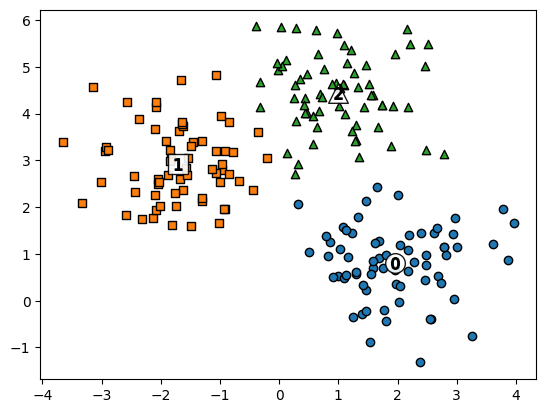

In [ ]:
# KMeans 객체를 이용해 X 데이터를 K-Means 클러스터링 수행
kmeans = KMeans(n_clusters=3, init='k-means++', max_iter=200, random_state=0)
cluster_labels = kmeans.fit_predict(X)
clusterDF['kmeans_label'] = cluster_labels

# cluster_centers_ 는 개별 클러스터의 중심 위치 좌표 시각화를 위해 추출
centers = kmeans.cluster_centers_
unique_labels = np.unique(cluster_labels)

markers=['o', 's', '^', 'P', 'D', 'H', 'x']

# 군집된 label 유형별로 iteration 하면서 marker 별로 scatter plot 수행.
for label in unique_labels:
    label_cluster = clusterDF[clusterDF['kmeans_label']==label]
    center_x_y = centers[label]
    plt.scatter(x=label_cluster['ftr1'], y=label_cluster['ftr2'], edgecolor='k',
                marker=markers[label] )

    # 군집별 중심 위치 좌표 시각화
    plt.scatter(x=center_x_y[0], y=center_x_y[1], s=200, color='white',
                alpha=0.9, edgecolor='k', marker=markers[label])
    plt.scatter(x=center_x_y[0], y=center_x_y[1], s=70, color='k', edgecolor='k',
                marker='$%d$' % label)

plt.show()

In [ ]:
print(clusterDF.groupby('target')['kmeans_label'].value_counts())

target  kmeans_label
0       2               66
        1                1
1       0               67
2       1               65
        0                1
Name: count, dtype: int64


make_blobs()는 cluster_std 파라미터로 데이터의 분포도 조절

## 군집평가

- 정답 레이블이 있으면 군집화 결과를 실제 품종과 비교 가능 하지만 대부분의 군집화 데이터에는 이런 레이블이 없음
- 군집화: 데이터에 숨어 있는 그룹을 찾는 방법
➡ 같은 클래스 안에서 더 세분화된 그룹을 찾거나, 서로 다른 클래스의 데이터를 하나의 그룹으로 묶을 수 있음
- 단일 지표로 성능을 정확히 판단하기 어렵
➡ 대표적인 평가 방법인 실루엣 분석은 같은 군집의 데이터가 얼마나 가까운지, 다른 군집과 얼마나 잘 분리되어 있는지를 살펴봄

**실루엣 분석의 개요**
 같은 군집의 데이터가 얼마나 가깝게 모여 있고, 다른 군집과 얼마나 잘 분리되어 있는지 평가하는 방법

**실루엣 계수**

데이터 포인트 $i$의 실루엣 계수는 두 평균 거리를 사용해 계산한다.

- $a(i)$는 포인트 $i$와 같은 군집에 속한 다른 포인트들까지의 평균 거리다.
- $b(i)$는 포인트 $i$에서 다른 군집 각각의 포인트들까지 평균 거리를 구했을 때, 그중 가장 작은 값이다.

$$
s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}
$$

**계수 해석**

- 1에 가까울수록 같은 군집의 데이터와 가깝고 다른 군집과 잘 분리되어 있다.
- 0에 가까울수록 소속 군집과 가장 가까운 다른 군집까지의 평균 거리가 비슷하다.
- 음수이면 소속 군집보다 평균 거리가 더 짧은 다른 군집이 있다.

**실루엣 계수의 해석과 활용**

실루엣 계수는 -1에서 1 사이의 값을 가진다.

- 1에 가까울수록 같은 군집의 데이터와 가깝고 다른 군집과 잘 분리되어 있다.
- 0에 가까울수록 소속 군집과 가장 가까운 다른 군집까지의 평균 거리가 비슷하다.
- 음수이면 소속 군집보다 평균 거리가 더 짧은 다른 군집이 있다.

**사이킷런 함수**

두 함수 모두 피처 데이터 `X`와 군집 레이블 labels를 입력받으며, 기본 거리 척도는 유클리드 거리다.

**군집화 결과를 평가하는 기준**

1. 전체 평균은 1에 가까울수록 군집 간 분리가 잘 이루어진 것으로 볼 수 있다.
2. 군집별 평균도 함께 확인한다. 전체 평균이 높아도 일부 군집의 평균이 낮다면 해당 군집은 데이터가 잘 뭉쳐 있지 않거나 다른 군집과의 분리가 약할 수 있다.

**붓꽃 데이터 세트를 이용한 군집 평가**

In [ ]:
from sklearn.preprocessing import scale
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
# 실루엣 분석 평가 지표 값을 구하기 위한 API 추가
from sklearn.metrics import silhouette_samples, silhouette_score
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

%matplotlib inline

iris = load_iris()
feature_names = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
irisDF = pd.DataFrame(data=iris.data, columns=feature_names)
kmeans = KMeans(n_clusters=3, init='k-means++', max_iter=300, random_state=0).fit(irisDF)
irisDF['cluster'] = kmeans.labels_

# iris의 모든 개별 데이터에 실루엣 계수 값을 구함.
score_samples = silhouette_samples(iris.data, irisDF['cluster'])
print('silhouette_samples( ) return 값의 shape', score_samples.shape)

# irisDF에 실루엣 계수 칼럼 추가
irisDF['silhouette_coeff'] = score_samples

# 모든 데이터의 평균 실루엣 계수 값을 구함.
average_score = silhouette_score(iris.data, irisDF['cluster'])
print('붓꽃 데이터 세트 Silhouette Analysis Score:{0:.3f}'.format(average_score))
irisDF.head(3)

silhouette_samples( ) return 값의 shape (150,)
붓꽃 데이터 세트 Silhouette Analysis Score:0.551


,sepal_length,sepal_width,petal_length,petal_width,cluster,silhouette_coeff
0,5.1,3.5,1.4,0.2,1,0.852582
1,4.9,3.0,1.4,0.2,1,0.814916
2,4.7,3.2,1.3,0.2,1,0.828797


In [ ]:
irisDF.groupby('cluster')['silhouette_coeff'].mean()

,silhouette_coeff
cluster,
0,0.422323
1,0.797604
2,0.436842


*실루엣 그래프로 적절한 군집 개수 찾기*

전체 평균 실루엣 계수가 높아도 일부 군집의 데이터가 넓게 퍼져 있거나 이웃 군집과 가깝게 붙어 있을 수 있다. 따라서 K-Means의 군집 개수를 정할 때는 **전체 평균과 군집별 실루엣 계수 분포**를 함께 확인한다.

**실루엣 그래프 읽는 법**

- **x축**은 개별 데이터 포인트의 실루엣 계수를 나타낸다.
- **y축**은 군집별로 데이터를 묶어 보여 준다. 각 띠의 두께는 해당 군집의 데이터 개수를 나타낸다.
- **세로 점선**은 전체 평균 실루엣 계수를 나타낸다. 각 군집에서 점선 왼쪽에 놓인 데이터가 얼마나 많은지 확인한다.


이 예제에서는 군집별 응집도와 분리도를 함께 고려해 **4개**를 적절한 군집 개수로 판단한다. `visualize_silhouette([2, 3, 4, 5], X_features)`를 사용하면 후보별 실루엣 그래프를 비교할 수 있다.

In [ ]:
# visualize_silhouette([2, 3, 4, 5], X_features)

In [ ]:
#p.448

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_samples, silhouette_score
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np


def visualize_silhouette(cluster_list, X):
    from matplotlib import pyplot as plt

    for n_clusters in cluster_list:
        fig, ax1 = plt.subplots(1)
        fig.set_size_inches(6, 4)

        ax1.set_xlim([-0.1, 1])
        ax1.set_ylim([0, len(X) + (n_clusters + 1) * 10])

        kmeans = KMeans(n_clusters=n_clusters, random_state=10)
        cluster_labels = kmeans.fit_predict(X)

        silhouette_vals = silhouette_samples(X, cluster_labels)
        silhouette_avg = silhouette_score(X, cluster_labels)

        y_lower = 10
        for i in range(n_clusters):
            ith_silhouette_vals = silhouette_vals[cluster_labels == i]
            ith_silhouette_vals.sort()

            size_cluster_i = ith_silhouette_vals.shape[0]
            y_upper = y_lower + size_cluster_i

            color = cm.nipy_spectral(float(i) / n_clusters)
            ax1.fill_betweenx(np.arange(y_lower, y_upper),
                              0, ith_silhouette_vals,
                              facecolor=color, edgecolor=color, alpha=0.7)

            ax1.text(-0.05, y_lower + 0.5 * size_cluster_i, str(i))
            y_lower = y_upper + 10

        ax1.axvline(x=silhouette_avg, color="red", linestyle="--")
        ax1.set_title(f"Silhouette plot for {n_clusters} clusters")
        ax1.set_xlabel("Silhouette coefficient values")
        ax1.set_ylabel("Cluster label")

        plt.tight_layout()
        plt.show()

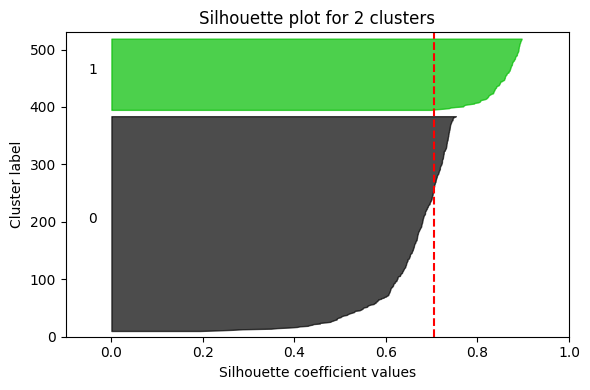

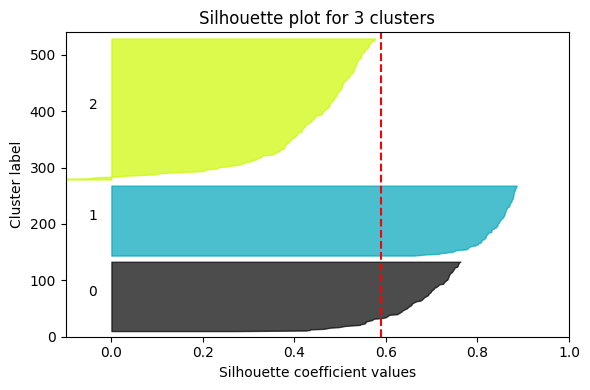

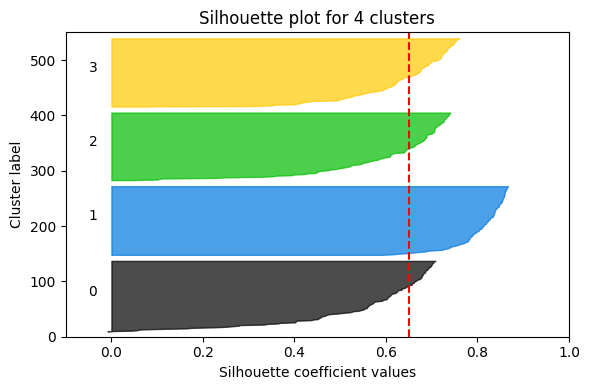

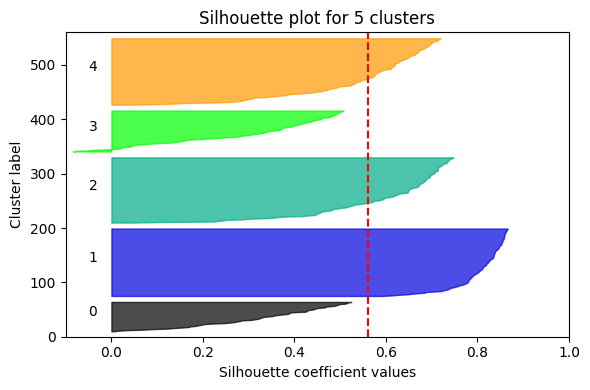

In [ ]:
# make_blobs를 통해 군집화를 위한 4개의 군집 중심의 500개 2차원 데이터 세트 생성
from sklearn.datasets import make_blobs
X, y = make_blobs(n_samples=500, n_features=2, centers=4, cluster_std=1,
                  center_box=(-10.0, 10.0), shuffle=True, random_state=1)

# 군집 개수가 2개, 3개, 4개, 5개일 때의 군집별 실루엣 계수 평균값을 시각화
visualize_silhouette([2, 3, 4, 5], X)

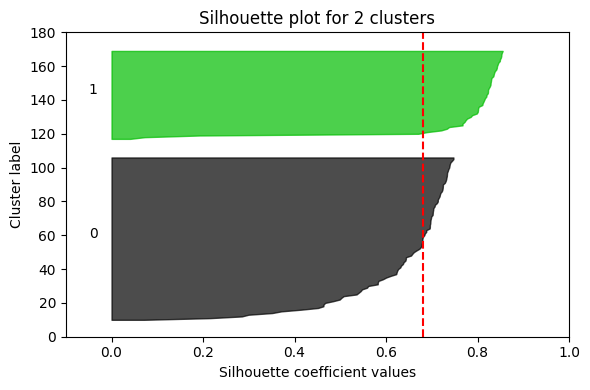

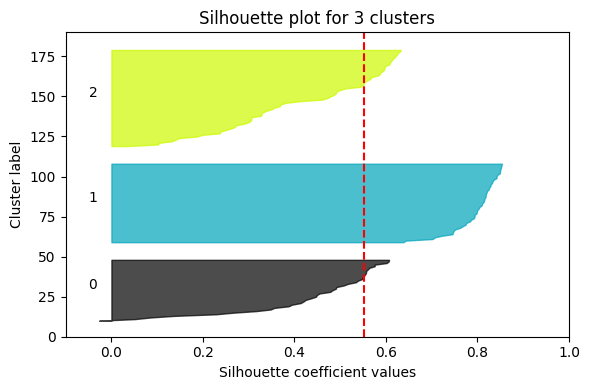

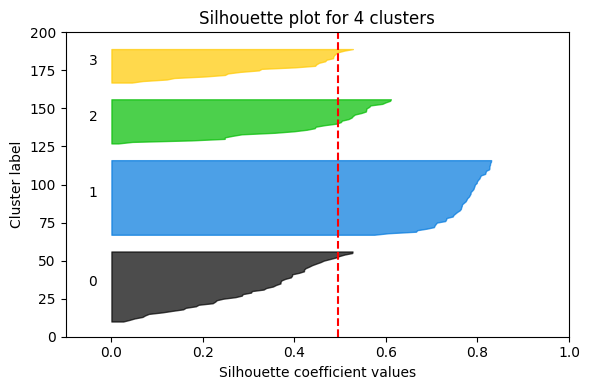

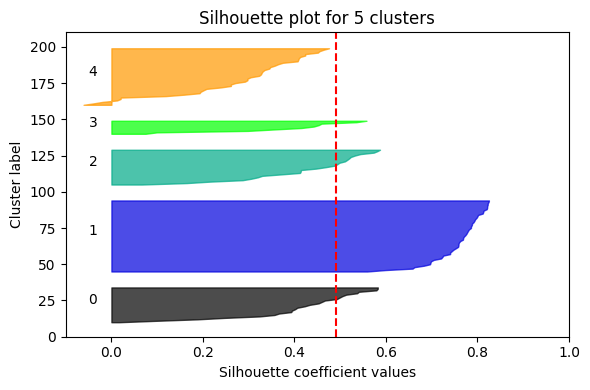

In [ ]:
from sklearn.datasets import load_iris
iris=load_iris()
visualize_silhouette([2, 3, 4, 5], iris.data)

**대용량 데이터에서의 실루엣 분석**

- 실루엣 계수로 K-평균 군집화 결과를 직관적으로 평가할 수 있다.
- 데이터 포인트 간 거리를 반복해서 계산하므로 데이터가 많아질수록 실행 시간과 메모리 사용량이 늘어난다.
- 데이터가 수만 건 이상이면 개인용 PC에서 메모리 부족이 발생할 수 있다. 이때는 각 군집에서 일부 데이터를 무작위로 추출해 실루엣 계수를 계산할 수 있다.

## 평균 이동
**평균 이동(Mean Shift)의 개요**

평균 이동은 현재 위치를 주변 데이터의 평균 위치로 반복해서 옮겨, 데이터 밀도가 높은 지점을 군집 중심으로 찾는 방법이다. 군집 개수는 미리 지정하지 않으며, 이동이 수렴한 위치를 바탕으로 정해진다.

**커널 밀도 추정(KDE)**

각 관측값에 가우시안 함수 같은 커널을 적용하고, 그 결과를 합쳐 확률 밀도를 추정한다. 평균 이동은 이렇게 추정한 밀도에서 데이터가 집중된 지점을 군집 중심으로 찾는다.

$$
\hat{f}(x) = \frac{1}{nh}\sum_{i=1}^{n} K\left(\frac{x-x_i}{h}\right)
$$

$n$은 관측값의 개수, $K$는 커널 함수, $x_i$는 개별 관측값, $h$는 대역폭이다.

**대역폭(`bandwidth`)의 영향**

- 대역폭이 작으면 밀도 곡선이 뾰족해지고 군집이 많아지는 경향이 있다. 너무 작으면 과적합이 발생할 수 있다.
- 대역폭이 크면 밀도 곡선이 부드러워지고 가까운 봉우리들이 합쳐져 군집이 적어지는 경향이 있다. 너무 크면 과소적합이 발생할 수 있다.

사이킷런에서는 `MeanShift`의 `bandwidth`로 대역폭을 설정하며, `estimate_bandwidth()`로 데이터에서 대역폭을 추정할 수 있다.

In [ ]:
import numpy as np
from sklearn.datasets import make_blobs
from sklearn.cluster import MeanShift

X, y = make_blobs(n_samples=200, n_features=2, centers=3, cluster_std=0.7, random_state=0)

meanshift= MeanShift(bandwidth=0.8)
cluster_labels = meanshift.fit_predict(X)
print('cluster labels 유형:', np.unique(cluster_labels))

cluster labels 유형: [0 1 2 3 4 5]


In [ ]:
meanshift= MeanShift(bandwidth=1)
cluster_labels = meanshift.fit_predict(X)
print('cluster labels 유형:', np.unique(cluster_labels))

cluster labels 유형: [0 1 2]


In [ ]:
from sklearn.cluster import estimate_bandwidth

bandwidth = estimate_bandwidth(X)
print('bandwidth 값:', round(bandwidth,3))

bandwidth 값: 1.816


In [ ]:
import pandas as pd

clusterDF = pd.DataFrame(data=X, columns=['ftr1', 'ftr2'])
clusterDF['target'] = y

# estimate_bandwidth()로 최적의 bandwidth 계산
best_bandwidth = estimate_bandwidth(X)

meanshift= MeanShift(bandwidth=best_bandwidth)
cluster_labels = meanshift.fit_predict(X)
print('cluster labels 유형:',np.unique(cluster_labels))

cluster labels 유형: [0 1 2]


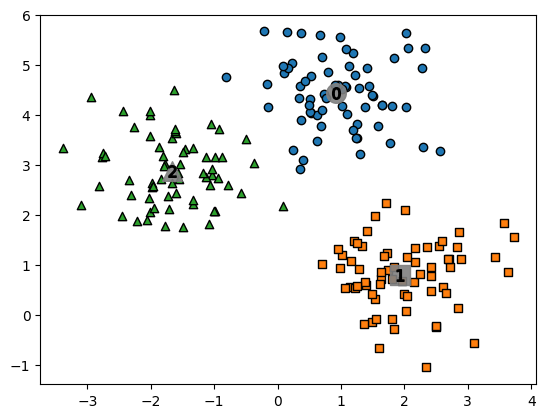

In [ ]:
import matplotlib.pyplot as plt
%matplotlib inline

clusterDF['meanshift_label'] = cluster_labels
centers = meanshift.cluster_centers_
unique_labels = np.unique(cluster_labels)
markers=['o', 's', '^', 'x', '*']

for label in unique_labels:
    label_cluster = clusterDF[clusterDF['meanshift_label']==label]
    center_x_y = centers[label]
        # 군집별로 다른 마커로 산점도 적용
    plt.scatter(x=label_cluster['ftr1'], y=label_cluster['ftr2'], edgecolor='k', marker=markers[label])

    # 군집별 중심 표현
    plt.scatter(x=center_x_y[0], y=center_x_y[1], s=200, color='gray', alpha=0.9,
                marker=markers[label])
    plt.scatter(x=center_x_y[0], y=center_x_y[1], s=70, color='k', edgecolor='k', marker='$%d$' % label)

plt.show()

In [ ]:
print(clusterDF.groupby('target')['meanshift_label'].value_counts())

target  meanshift_label
0       0                  67
1       1                  67
2       2                  66
Name: count, dtype: int64


## GMM
**GMM(Gaussian Mixture Model)의 개요**

GMM은 전체 데이터가 여러 개의 가우시안 분포(정규분포)가 섞여 만들어졌다고 가정하는 군집화 방법이다. 각 분포를 하나의 군집으로 보고, 각 데이터가 어느 분포에 속할 가능성이 높은지 계산한다.

**가우시안 분포**

정규분포는 평균 $\mu$를 중심으로 좌우 대칭인 종 모양을 가진다. 평균에서 양쪽으로 표준편차 1배, 2배, 3배 이내에 각각 약 68.27%, 95.45%, 99.73%의 확률이 포함된다. 평균이 0이고 표준편차가 1인 정규분포를 표준정규분포라고 한다.

**GMM의 군집화 과정**

1. 전체 데이터에 섞여 있는 각 정규분포의 평균, 분산, 혼합 비율을 추정한다.
2. 각 데이터가 각각의 분포에 속할 확률을 계산한다.
3. 군집 레이블이 필요하면 소속 확률이 가장 높은 분포에 할당한다.

GMM은 **EM(Expectation-Maximization)** 알고리즘을 사용해 소속 확률 계산과 분포의 모수 갱신을 반복한다. 사이킷런에서는 `GaussianMixture` 클래스로 GMM을 적용할 수 있다.

**GMM을 이용한 붓꽃 데이터 세트 군집화**

In [ ]:
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
%matplotlib inline

iris = load_iris()
feature_names = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']

# 좀 더 편리한 데이터 Handling을 위해 DataFrame으로 변환
irisDF = pd.DataFrame(data=iris.data, columns=feature_names)
irisDF['target'] = iris.target

In [ ]:
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=3, random_state=0).fit(iris.data)
gmm_cluster_labels = gmm.predict(iris.data)

# 군집화 결과를 irisDF의 'gmm_cluster' 칼럼명으로 저장
irisDF['gmm_cluster'] = gmm_cluster_labels
irisDF['target'] = iris.target

# target 값에 따라 gmm_cluster 값이 어떻게 매핑됐는지 확인.
iris_result = irisDF.groupby(['target'])['gmm_cluster'].value_counts()
print(iris_result)

target  gmm_cluster
0       1              50
1       0              45
        2               5
2       2              50
Name: count, dtype: int64


In [ ]:
kmeans = KMeans(n_clusters=3, init='k-means++', max_iter=300, random_state=0).fit(iris.data)
kmeans_cluster_labels = kmeans.predict(iris.data)
irisDF['kmeans_cluster'] = kmeans_cluster_labels
iris_result = irisDF.groupby(['target'])['kmeans_cluster'].value_counts()
print(iris_result)

target  kmeans_cluster
0       1                 50
1       0                 47
        2                  3
2       2                 36
        0                 14
Name: count, dtype: int64



**GMM과 K-평균의 비교**

- K-평균은 각 데이터를 가장 가까운 중심점에 할당한다. 군집이 중심을 기준으로 둥글게 모여 있고 서로 잘 떨어져 있을 때 효과적이다.
- 예제에서는 `make_blobs()`로 군집 3개를 만들고 `cluster_std=0.5`로 설정해 각 군집의 데이터가 중심 주변에 모이도록 했다.
- 데이터가 길쭉한 타원형으로 퍼져 있으면 K-평균으로 군집을 구분하기 어려울 수 있다. GMM은 각 군집의 공분산을 추정해 타원의 퍼짐과 방향을 반영할 수 있다.

**군집 시각화 함수 `visualize_cluster_plot()`**

- `clusterobj`는 학습된 `KMeans` 또는 `GaussianMixture` 객체다. `make_blobs()`로 생성한 데이터의 원래 레이블을 시각화할 때는 `None`을 전달한다.
- `dataframe`은 피처와 레이블을 담은 DataFrame이다.
- `label_name`은 색이나 마커로 구분할 레이블의 칼럼명이다. 원래 레이블을 표시할 때는 `target`을 사용한다.
- `iscenter`는 군집 중심 표시 여부다. 객체가 중심 좌표를 제공하면 `True`로 설정해 표시할 수 있다.

In [ ]:
#p.460
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.datasets import make_blobs
%matplotlib inline


def visualize_cluster_plot(cluster_result=None, dataframe=None, label_name='target', iscenter=True):
    if dataframe is None:
        print("Error: DataFrame is required.")
        return

    unique_labels = np.unique(dataframe[label_name])
    markers = ['o', 's', '^', 'x', '*', 'D', '+', 'v', '<', '>']

    for label in unique_labels:
        label_cluster = dataframe[dataframe[label_name] == label]
        plt.scatter(x=label_cluster['ftr1'], y=label_cluster['ftr2'], edgecolor='k',
                    marker=markers[label % len(markers)])

        if iscenter and cluster_result is not None and hasattr(cluster_result, 'cluster_centers_'):
            # Assuming cluster_result has a .cluster_centers_ attribute
            center_x_y = cluster_result.cluster_centers_[label]
            plt.scatter(x=center_x_y[0], y=center_x_y[1], s=200, color='gray', alpha=0.9,
                        marker=markers[label % len(markers)])
            plt.scatter(x=center_x_y[0], y=center_x_y[1], s=70, color='k', edgecolor='k',
                        marker='$%d$' % label)

    plt.show()

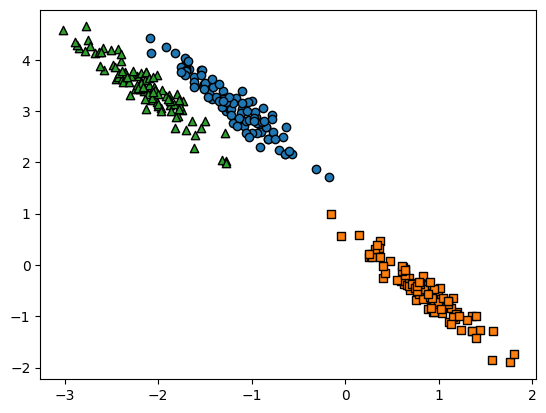

In [ ]:
from sklearn.datasets import make_blobs

# make_blobs()로 300개의 데이터 세트, 3개의 군집 세트, cluster_std=0.5를 만듦.
X, y = make_blobs(n_samples=300, n_features=2, centers=3, cluster_std=0.5, random_state=0)

# 길게 늘어난 타원형의 데이터 세트를 생성하기 위해 변환함.
transformation = [[0.60834549, -0.63667341], [-0.40887718, 0.85253229]]
X_aniso = np.dot(X, transformation)

# feature 데이터 세트와 make_blobs( )의 y 결괏값을 DataFrame으로 저장
clusterDF = pd.DataFrame(data=X_aniso, columns=['ftr1', 'ftr2'])
clusterDF['target'] = y

# 생성된 데이터 세트를 target별로 다른 마커로 표시해 시각화함
visualize_cluster_plot(None, clusterDF, 'target', iscenter=False)

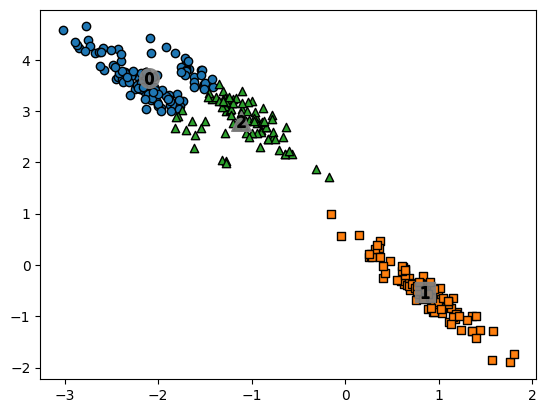

In [ ]:
# 3개의 군집 기반 Kmeans를 X_aniso 데이터 세트에 적용
kmeans = KMeans(3, random_state=0)
kmeans_label = kmeans.fit_predict(X_aniso)
clusterDF['kmeans_label'] = kmeans_label

visualize_cluster_plot(kmeans, clusterDF, 'kmeans_label', iscenter=True)

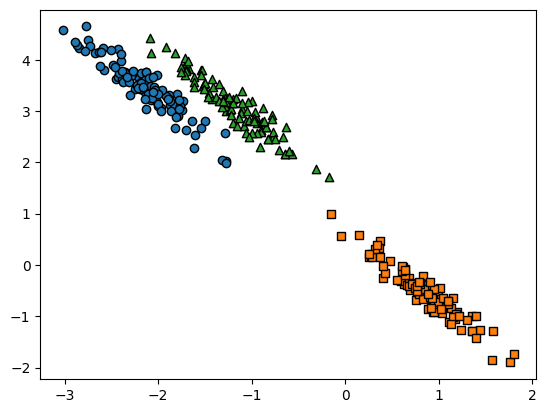

In [ ]:
# 3개의 n_components 기반 GMM을 X_aniso 데이터 세트에 적용
gmm = GaussianMixture(n_components=3, random_state=0)
gmm_label = gmm.fit(X_aniso).predict(X_aniso)
clusterDF['gmm_label'] = gmm_label

# GaussianMixture는 cluster_centers_ 속성이 없으므로 iscenter를 False로 설정.
visualize_cluster_plot(gmm, clusterDF, 'gmm_label', iscenter=False)

In [ ]:
print('### KMeans Clustering ###')
print(clusterDF.groupby('target')['kmeans_label'].value_counts())
print('\n### Gaussian Mixture Clustering ###')
print(clusterDF.groupby('target')['gmm_label'].value_counts())

### KMeans Clustering ###
target  kmeans_label
0       2                73
        0                27
1       1               100
2       0                86
        2                14
Name: count, dtype: int64

### Gaussian Mixture Clustering ###
target  gmm_label
0       2            100
1       1            100
2       0            100
Name: count, dtype: int64


**DBSCAN의 개요**

DBSCAN은 데이터가 밀집된 영역을 군집으로 묶는 밀도 기반 군집화 알고리즘이다. 군집 개수를 미리 지정할 필요가 없으며, 동심원처럼 복잡한 모양의 군집도 찾을 수 있다.

**주요 파라미터**

- `eps`는 한 점을 기준으로 이웃을 찾는 반경이다.
- `min_samples`는 핵심 포인트가 되기 위해 `eps` 반경 안에 있어야 하는 최소 데이터 개수다. 기준점 자신도 포함한다.

**포인트의 유형**

- 핵심 포인트(Core Point)는 `eps` 반경 안의 데이터 개수가 `min_samples` 이상인 점이다.
- 경계 포인트(Border Point)는 핵심 포인트가 되기 위한 개수 조건은 충족하지 않지만, 핵심 포인트의 `eps` 반경 안에 있는 점이다.
- 잡음 포인트(Noise Point)는 핵심 포인트와 경계 포인트 어디에도 해당하지 않는 점이다.

**군집이 만들어지는 과정**

서로 `eps` 반경 안에 있는 핵심 포인트를 연결하면서 군집을 확장하고, 각 핵심 포인트의 반경 안에 있는 경계 포인트도 군집에 포함한다. 그림에서는 P1과 P2가 핵심 포인트로 연결되고, P3는 P2에 인접해 경계 포인트로 포함된다. P5는 잡음 포인트로 남는다.

**DBSCAN 적용하기 - 붓꽃 데이터세트**

In [ ]:
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.6, min_samples=8, metric='euclidean')
dbscan_labels = dbscan.fit_predict(iris.data)

irisDF['dbscan_cluster'] = dbscan_labels
irisDF['target'] = iris.target

iris_result = irisDF.groupby(['target'])['dbscan_cluster'].value_counts()
print(iris_result)

target  dbscan_cluster
0        0                49
        -1                 1
1        1                46
        -1                 4
2        1                42
        -1                 8
Name: count, dtype: int64


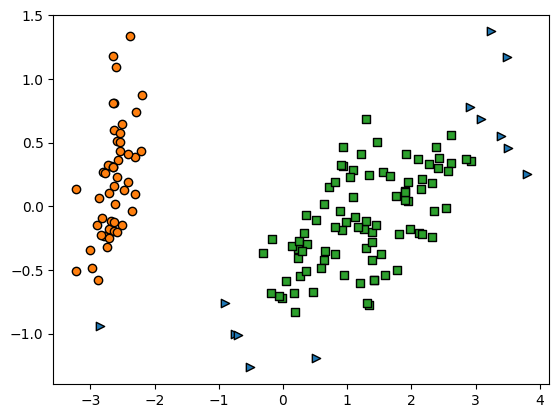

In [ ]:
from sklearn.decomposition import PCA
# 2차원으로 시각화하기 위해 PCA n_components=2로 피처 데이터 세트 변환
pca = PCA(n_components=2, random_state=0)
pca_transformed = pca.fit_transform(iris.data)
# visualize_cluster_plot( ) 함수는 ftr1, ftr2 칼럼을 좌표에 표현하므로 PCA 변환값을 해당 칼럼으로 생성
irisDF['ftr1'] = pca_transformed[:, 0]
irisDF['ftr2'] = pca_transformed[:, 1]

visualize_cluster_plot(dbscan, irisDF, 'dbscan_cluster', iscenter=False)

target  dbscan_cluster
0        0                50
1        1                50
2        1                47
        -1                 3
Name: count, dtype: int64


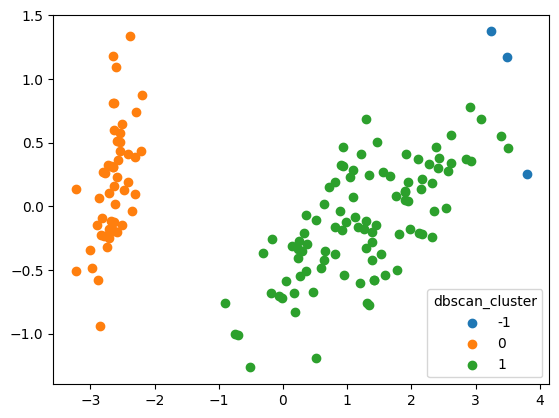

In [ ]:
def visualize_cluster_2d(dataframe, label_name, centers=None, legend=True):
    fig, ax = plt.subplots()
    for label, group in dataframe.groupby(label_name):
        ax.scatter(group['ftr1'], group['ftr2'], label='Noise' if label == -1 else str(label))
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], marker='x', color='black')
    if legend:
        ax.legend(title=label_name)
    plt.show()

from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.8, min_samples=8, metric='euclidean')
dbscan_labels = dbscan.fit_predict(iris.data)

irisDF['dbscan_cluster'] = dbscan_labels
irisDF['target'] = iris.target

iris_result = irisDF.groupby(['target'])['dbscan_cluster'].value_counts()
print(iris_result)

visualize_cluster_2d(irisDF, 'dbscan_cluster', centers=None, legend=True)

In [ ]:
dbscan = DBSCAN(eps=0.6, min_samples=16, metric='euclidean')

In [ ]:
dbscan_labels = dbscan.fit_predict(iris.data)

irisDF['dbscan_cluster'] = dbscan_labels
irisDF['target'] = iris.target

iris_result = irisDF.groupby(['target'])['dbscan_cluster'].value_counts()
print(iris_result)

target  dbscan_cluster
0        0                48
        -1                 2
1        1                44
        -1                 6
2        1                36
        -1                14
Name: count, dtype: int64


**DBSCAN 적용하기**

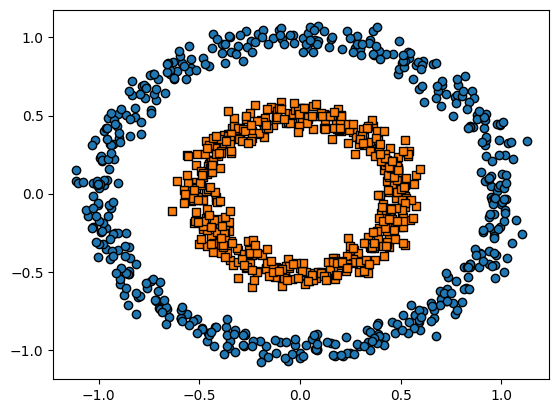

In [ ]:
from sklearn.datasets import make_circles

X, y = make_circles(n_samples=1000, shuffle=True, noise=0.05, random_state=0, factor=0.5)
clusterDF = pd.DataFrame(data=X, columns=['ftr1', 'ftr2'])
clusterDF['target'] = y

visualize_cluster_plot(None, clusterDF, 'target', iscenter=False)

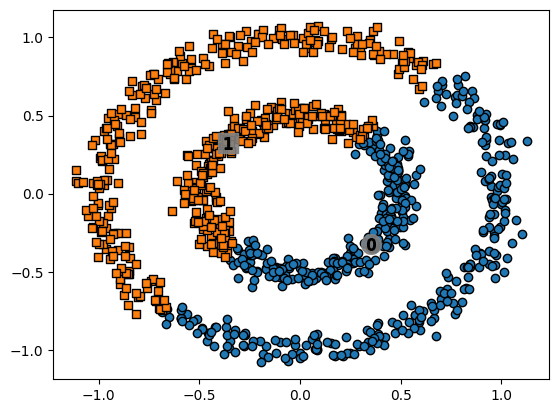

In [ ]:
# KMeans로 make_circles( ) 데이터 세트를 군집화 수행.
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=2, max_iter=1000, random_state=0)
kmeans_labels = kmeans.fit_predict(X)
clusterDF['kmeans_cluster'] = kmeans_labels

visualize_cluster_plot(kmeans, clusterDF, 'kmeans_cluster', iscenter=True)

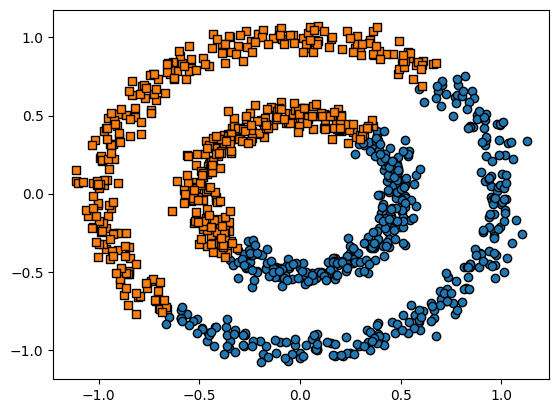

In [ ]:
# GMM으로 make_circles( ) 데이터 세트를 군집화 수행.
from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=2, random_state=0)
gmm_label = gmm.fit(X).predict(X)
clusterDF['gmm_cluster'] = gmm_label

visualize_cluster_plot(gmm, clusterDF, 'gmm_cluster', iscenter=False)

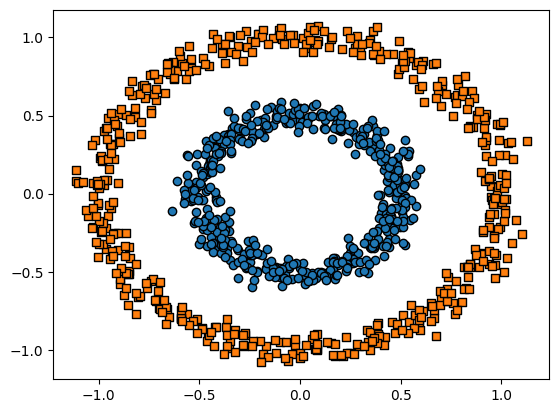

In [ ]:
# DBSCAN으로 make_circles( ) 데이터 세트 군집화 수행.
from sklearn.cluster import DBSCAN

dbscan = DBSCAN(eps=0.2, min_samples=10, metric='euclidean')
dbscan_labels = dbscan.fit_predict(X)
clusterDF['dbscan_cluster'] = dbscan_labels
visualize_cluster_plot(dbscan, clusterDF, 'dbscan_cluster', iscenter=False)

## 군집화 실습 - 고객 세그먼테이션

**고객 세그먼테이션**

고객 세그먼테이션은 구매 행동이나 고객 특성을 기준으로 고객을 여러 그룹으로 나누는 기법이다. 각 그룹에 맞는 상품 추천, 프로모션, VIP 혜택 등을 제공하는 타깃 마케팅에 활용한다.

**RFM 기법**

- `Recency`(R)는 가장 최근 구매일부터 분석 기준일까지 지난 기간이다.
- `Frequency`(F)는 분석 기간 동안의 구매 횟수다.
- `Monetary Value`(M)는 분석 기간 동안의 총 구매 금액이다.

**실습 데이터 준비**

UCI의 Online Retail 데이터는 영국 온라인 소매업체의 거래 내역을 담고 있다. `Online Retail.xlsx`를 노트북과 같은 폴더에 저장하고, 판다스의 `read_excel()`로 불러온다. 거래 데이터를 정제한 뒤 고객별 RFM 값을 계산해 군집화에 사용한다.

In [ ]:
import pandas as pd
import datetime
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

retail_df = pd.read_excel(io='/content/Online Retail.xlsx')
retail_df.head(3)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom


In [ ]:
retail_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


In [ ]:
retail_df = retail_df[retail_df['Quantity'] > 0]
retail_df = retail_df[retail_df['UnitPrice'] > 0]
retail_df = retail_df[retail_df['CustomerID'].notnull()]
print(retail_df.shape)
retail_df.isnull().sum()

(397884, 8)


,0
InvoiceNo,0
StockCode,0
Description,0
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,0
Country,0


In [ ]:
retail_df['Country'].value_counts()[:5]

,count
Country,
United Kingdom,354321
Germany,9040
France,8341
EIRE,7236
Spain,2484


In [ ]:
retail_df = retail_df[retail_df['Country']=='United Kingdom']
print(retail_df.shape)

(354321, 8)


**RFM 기반 데이터 가공**

In [ ]:
retail_df['sale_amount'] = retail_df['Quantity'] * retail_df['UnitPrice']
retail_df['CustomerID'] = retail_df['CustomerID'].astype(int)

In [ ]:
print(retail_df['CustomerID'].value_counts().head(5))
print(retail_df.groupby('CustomerID')['sale_amount'].sum().sort_values(ascending=False)[:5])

CustomerID
17841    7847
14096    5111
12748    4595
14606    2700
15311    2379
Name: count, dtype: int64
CustomerID
18102    259657.30
17450    194550.79
16446    168472.50
17511     91062.38
16029     81024.84
Name: sale_amount, dtype: float64


In [ ]:
retail_df.groupby(['InvoiceNo', 'StockCode'])['InvoiceNo'].count().mean()

np.float64(1.028702077315023)

In [ ]:
# DataFrame의 groupby()의 multiple 연산을 위해 agg() 이용
# Recency는 InvoiceDate 칼럼의 max()에서 데이터 가공
# Frequency는 InvoiceNo 칼럼의 count(), Monetary value는 sale_amount 칼럼의 sum()
aggregations = {
    'InvoiceDate': 'max',
    'InvoiceNo': 'count',
    'sale_amount': 'sum'
}
cust_df = retail_df.groupby('CustomerID').agg(aggregations)
# groupby된 결과 칼럼 값을 Recency, Frequency, Monetary로 변경
cust_df = cust_df.rename(columns = {'InvoiceDate':'Recency',
                                    'InvoiceNo':'Frequency',
                                    'sale_amount':'Monetary'
                                   }
                         )
cust_df = cust_df.reset_index()
cust_df.head(3)

,CustomerID,Recency,Frequency,Monetary
0,12346,2011-01-18 10:01:00,1,77183.60
1,12747,2011-12-07 14:34:00,103,4196.01
2,12748,2011-12-09 12:20:00,4595,33719.73


In [ ]:
import datetime as dt

cust_df['Recency'] = dt.datetime(2011, 12, 10) - cust_df['Recency']
cust_df['Recency'] = cust_df['Recency'].apply(lambda x: x.days+1)
print('cust_df 로우와 칼럼 건수는 ', cust_df.shape)
cust_df.head(3)

cust_df 로우와 칼럼 건수는  (3920, 4)


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12747,3,103,4196.01
2,12748,1,4595,33719.73


**RFM 기반 고객 세그먼테이션**

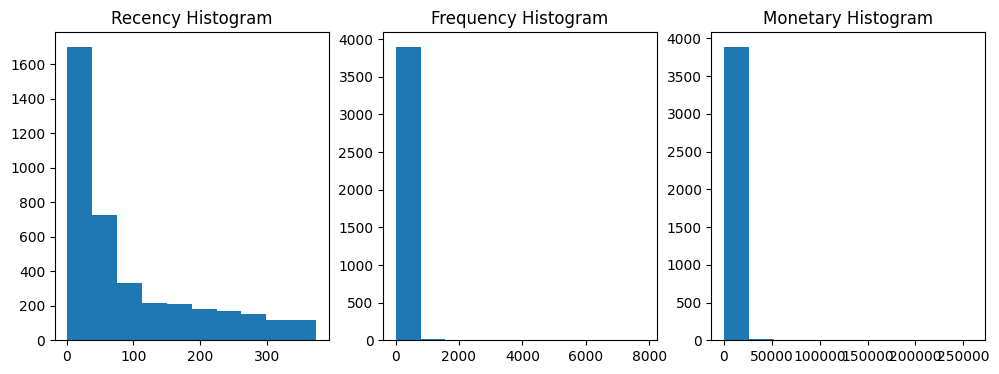

In [ ]:
fig, (ax1, ax2, ax3) = plt.subplots(figsize=(12, 4), nrows=1, ncols=3)
ax1.set_title('Recency Histogram')
ax1.hist(cust_df['Recency'])

ax2.set_title('Frequency Histogram')
ax2.hist(cust_df['Frequency'])

ax3.set_title('Monetary Histogram')
ax3.hist(cust_df['Monetary'])
plt.show()

In [ ]:
cust_df[['Recency', 'Frequency', 'Monetary']].describe()

,Recency,Frequency,Monetary
count,3920.000000,3920.000000,3920.000000
mean,92.742092,90.388010,1864.385601
std,99.533485,217.808385,7482.817477
min,1.000000,1.000000,3.750000
25%,18.000000,17.000000,300.280000
50%,51.000000,41.000000,652.280000
75%,143.000000,99.250000,1576.585000
max,374.000000,7847.000000,259657.300000


In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

X_features = cust_df[['Recency', 'Frequency', 'Monetary']].values
X_features_scaled = StandardScaler().fit_transform(X_features)

kmeans = KMeans(n_clusters=3, random_state=0)
labels = kmeans.fit_predict(X_features_scaled)
cust_df['cluster_label'] = labels

print('실루엣 스코어는 : {0:.3f}'.format(silhouette_score(X_features_scaled, labels)))

실루엣 스코어는 : 0.576


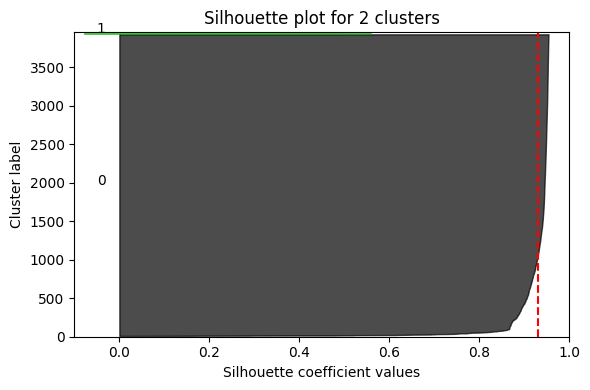

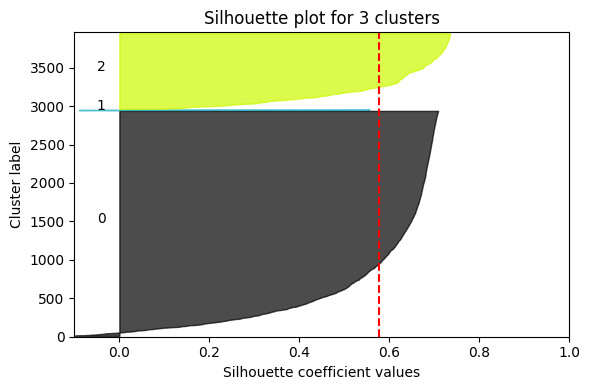

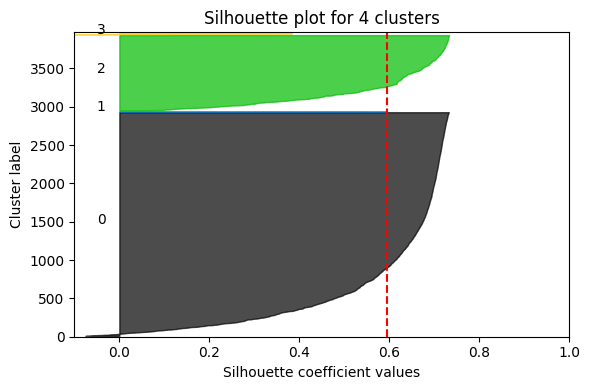

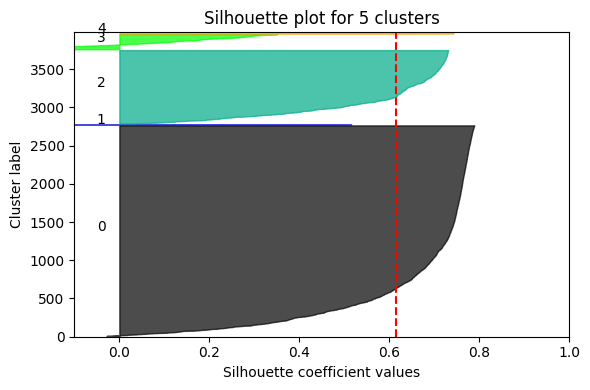

NameError: name 'visualize_kmeans_plot_multi' is not defined

In [ ]:
def visualize_kmeans_plot_multi(cluster_lists, X_features):
    pca_transformed = PCA(n_components=2).fit_transform(X_features)
    n_cols = len(cluster_lists)
    fig, axes = plt.subplots(1, n_cols, figsize=(4 * n_cols, 4), squeeze=False)
    markers = ['o', 's', '^', 'x', '*']

    for ax, n_clusters in zip(axes[0], cluster_lists):
        clusterer = KMeans(n_clusters=n_clusters, max_iter=500, random_state=0)
        cluster_labels = clusterer.fit_predict(pca_transformed)
        for label in np.unique(cluster_labels):
            points = pca_transformed[cluster_labels == label]
            ax.scatter(points[:, 0], points[:, 1], s=70,
                       marker=markers[label % len(markers)], label=f'Cluster {label}')
        ax.set_title(f'Number of Cluster : {n_clusters}')
        ax.legend(loc='upper right')

    plt.show()

visualize_silhouette([2, 3, 4, 5], X_features_scaled)
visualize_kmeans_plot_multi([2, 3, 4, 5], X_features_scaled)

**고객 군집화 결과와 로그 변환**

- 군집을 2개로 나누면 고객 유형이 너무 크게 묶였다. 3개 이상으로 늘리자 데이터가 적고 내부 분포가 넓으며 실루엣 계수도 낮은 군집이 생겼다.
- 소규모 군집에는 대량 주문을 한 일부 소매점의 거래가 포함됐다. 이런 극단값이 거리 기반 K-평균에 큰 영향을 주어, 군집 수를 늘려도 비슷한 고객만 반복해서 분리됐다.
- 고객 군집화의 목적은 구매 패턴이 비슷한 고객을 묶고, 각 그룹의 특성에서 새로운 고객 유형을 발견하는 데 있다.
- 큰 값의 영향을 줄이기 위해 RFM 변수에 로그 변환을 적용한 뒤, K-평균을 다시 수행해 변환 전후 결과를 비교한다.

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, silhouette_samples

# Recency, Frequency, Monetary 칼럼에 np.log1p()로 Log Transformation
cust_df['Recency_log'] = np.log1p(cust_df['Recency'])
cust_df['Frequency_log'] = np.log1p(cust_df['Frequency'])
cust_df['Monetary_log'] = np.log1p(cust_df['Monetary'])

# Log Transformation 데이터에 StandardScaler 적용
X_features = cust_df[['Recency_log', 'Frequency_log', 'Monetary_log']].values
X_features_scaled = StandardScaler().fit_transform(X_features)

kmeans = KMeans(n_clusters=3, random_state=0)
labels = kmeans.fit_predict(X_features_scaled)
cust_df['cluster_label'] = labels

print('실루엣 스코어는 : {0:.3f}'.format(silhouette_score(X_features_scaled, labels)))

실루엣 스코어는 : 0.303


## 정리

군집화 기법은 데이터의 모양, 밀도, 잡음 여부에 따라 선택한다.

- K-평균(K-Means)은 각 데이터를 가장 가까운 중심점에 할당하고, 군집의 평균 위치로 중심점을 갱신한다. 둥글고 잘 분리된 군집에 적합하다. 군집 개수를 미리 정해야 하며, 실루엣 계수로 여러 후보를 비교할 수 있다.
- 평균 이동(Mean Shift)은 중심점을 데이터 밀도가 높은 방향으로 반복해서 옮긴다. 군집 개수를 미리 정할 필요가 없고, 대역폭에 따라 결과가 달라진다. 영상에서 객체를 추적하는 데 활용할 수 있다.
- GMM은 데이터가 여러 가우시안 분포의 혼합으로 생성됐다고 가정한다. 각 데이터의 군집 소속 확률을 계산하며, 길쭉한 타원형 군집도 모델링할 수 있다. K-평균보다 계산 시간이 길어질 수 있다.
- DBSCAN은 밀도가 높은 핵심 포인트들을 연결하고 주변의 경계 포인트를 포함해 군집을 만든다. 동심원처럼 복잡한 모양의 군집을 찾을 수 있으며, 군집에 속하지 않는 점은 잡음으로 처리한다.